## 3. Generalised Sensitivity Model

### 3.1 Construction of Charging Windows

Charging windows are parameterised according to
their starting hour and nominal duration.

Local wall-clock timestamps determine whether
an interval belongs to a charging window, while
UTC timestamps preserve chronological ordering
and distinguish repeated hours during daylight-
saving transitions.

All availability scenarios are evaluated using
the same 364 local arrival dates.

In [3]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify project root
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define directories
processed_dir = project_root / "data" / "processed"
figures_dir = project_root / "outputs" / "figures"
tables_dir = project_root / "outputs" / "tables"

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Load validated electricity prices
df_hourly = pd.read_csv(
    processed_dir / "DE_LU_day_ahead_2025_hourly.csv"
)

# Restore timezone-aware timestamps
df_hourly["timestamp_utc"] = pd.to_datetime(
    df_hourly["timestamp_utc"],
    utc=True
)

df_hourly["timestamp_local"] = (
    df_hourly["timestamp_utc"]
    .dt.tz_convert("Europe/Berlin")
)

# Sort chronologically
df_hourly = (
    df_hourly
    .sort_values("timestamp_utc")
    .reset_index(drop=True)
)

# Import reference simulation results
reference_results = pd.read_csv(
    tables_dir / "annual_charging_results.csv",
    index_col="strategy"
)

# Basic integrity checks
assert len(df_hourly) == 8760
assert df_hourly["timestamp_utc"].is_unique
assert np.isfinite(df_hourly["price_eur_kwh"]).all()

print("Electricity price dataset successfully loaded.")
print("Observations:", len(df_hourly))
print("Reference simulation results successfully loaded.")

display(df_hourly.head())

Electricity price dataset successfully loaded.
Observations: 8760
Reference simulation results successfully loaded.


,timestamp_utc,price_eur_mwh,source_observations,timestamp_local,price_eur_kwh
0,2024-12-31 23:00:00+00:00,2.16,1,2025-01-01 00:00:00+01:00,0.00216
1,2025-01-01 00:00:00+00:00,1.60,1,2025-01-01 01:00:00+01:00,0.00160
2,2025-01-01 01:00:00+00:00,0.00,1,2025-01-01 02:00:00+01:00,0.00000
3,2025-01-01 02:00:00+00:00,-0.01,1,2025-01-01 03:00:00+01:00,-0.00001
4,2025-01-01 03:00:00+00:00,-0.01,1,2025-01-01 04:00:00+01:00,-0.00001


In [4]:
# Create wall-clock timestamps for window selection
market_data = df_hourly.copy()

market_data["wall_time"] = (
    market_data["timestamp_local"]
    .dt.tz_localize(None)
)


def build_charging_windows(
    start_hour,
    duration_hours
):
    """
    Construct charging windows for matched dates.

    Parameters
    ----------
    start_hour : int
        Local starting hour between 0 and 23.

    duration_hours : int
        Nominal charging availability in hours.

    Returns
    -------
    DataFrame containing feasible charging intervals.
    """

    if not 0 <= start_hour <= 23:
        raise ValueError("Invalid starting hour.")

    if not 1 <= duration_hours <= 24:
        raise ValueError("Invalid window duration.")

    records = []

    for date in session_dates:

        # Define local wall-clock boundaries
        start = (
            date
            + pd.Timedelta(hours=start_hour)
        )

        end = (
            start
            + pd.Timedelta(hours=duration_hours)
        )

        # Select feasible market intervals
        window = market_data.loc[
            (market_data["wall_time"] >= start)
            & (market_data["wall_time"] < end),
            [
                "timestamp_utc",
                "timestamp_local",
                "price_eur_kwh"
            ]
        ].copy()

        if window.empty:
            raise ValueError(
                f"No prices available for {date}."
            )

        window["session_id"] = date.strftime(
            "%Y-%m-%d"
        )

        window["season"] = season_mapping[date.month]

        window["interval_hours"] = TIME_STEP_HOURS

        records.append(window)

    windows = pd.concat(
        records,
        ignore_index=True
    )

    # Structural validation
    assert windows["session_id"].nunique() == N_SESSIONS

    assert not windows.duplicated(
        ["session_id", "timestamp_utc"]
    ).any()

    assert windows["timestamp_utc"].is_unique

    return windows

## 2. Reference Model Parameters

The reference parameters are retained from
Notebook 02.

The vehicle specification and annual residential
electricity requirement are adapted from
Lohr et al. (2025, pp. 6–7 and 11).

The availability windows and simplified retail
tariff represent modelling assumptions.

All sensitivity experiments hold the reference
parameters constant unless explicitly stated
otherwise.

In [5]:
# Reference vehicle parameters
BATTERY_CAPACITY_KWH = 45.0
MAX_CHARGING_POWER_KW = 11.0
ANNUAL_HOME_GRID_ENERGY_KWH = 1584.0
CHARGING_EFFICIENCY = 0.95
TARGET_SOC = 0.60

# Reference tariff parameters
CONSTANT_CHARGES_EUR_KWH = 0.20
FLAT_TARIFF_EUR_KWH = 0.30

# Reference availability
ARRIVAL_HOUR = 18
AVAILABILITY_HOURS = 12

# Simulation parameters
DAYS_PER_YEAR = 365
TIME_STEP_HOURS = 1.0
TOLERANCE = 1e-8

# Daily grid electricity requirement
DAILY_GRID_ENERGY_KWH = (
    ANNUAL_HOME_GRID_ENERGY_KWH / DAYS_PER_YEAR
)

# Use matched arrival dates across all experiments
session_dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-30",
    freq="D"
)

N_SESSIONS = len(session_dates)

ANNUALISATION_FACTOR = (
    DAYS_PER_YEAR / N_SESSIONS
)

# Meteorological seasons
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
}

season_order = [
    "Winter",
    "Spring",
    "Summer",
    "Autumn"
]

print("Reference parameters configured.")
print("Matched simulation dates:", N_SESSIONS)
print(f"Daily grid demand: {DAILY_GRID_ENERGY_KWH:.4f} kWh")
print(f"Annualisation factor: {ANNUALISATION_FACTOR:.6f}")

Reference parameters configured.
Matched simulation dates: 364
Daily grid demand: 4.3397 kWh
Annualisation factor: 1.002747


## 3. Generalised Sensitivity Model

### 3.1 Construction of Charging Windows

Charging windows are parameterised according to
their starting hour and nominal duration.

Local wall-clock timestamps determine whether
an interval belongs to a charging window, while
UTC timestamps preserve chronological ordering
and distinguish repeated hours during daylight-
saving transitions.

All availability scenarios are evaluated using
the same 364 local arrival dates.

In [6]:
# Create wall-clock timestamps for window selection
market_data = df_hourly.copy()

market_data["wall_time"] = (
    market_data["timestamp_local"]
    .dt.tz_localize(None)
)


def build_charging_windows(
    start_hour,
    duration_hours
):
    """
    Construct charging windows for matched dates.

    Parameters
    ----------
    start_hour : int
        Local starting hour between 0 and 23.

    duration_hours : int
        Nominal charging availability in hours.

    Returns
    -------
    DataFrame containing feasible charging intervals.
    """

    if not 0 <= start_hour <= 23:
        raise ValueError("Invalid starting hour.")

    if not 1 <= duration_hours <= 24:
        raise ValueError("Invalid window duration.")

    records = []

    for date in session_dates:

        # Define local wall-clock boundaries
        start = (
            date
            + pd.Timedelta(hours=start_hour)
        )

        end = (
            start
            + pd.Timedelta(hours=duration_hours)
        )

        # Select feasible market intervals
        window = market_data.loc[
            (market_data["wall_time"] >= start)
            & (market_data["wall_time"] < end),
            [
                "timestamp_utc",
                "timestamp_local",
                "price_eur_kwh"
            ]
        ].copy()

        if window.empty:
            raise ValueError(
                f"No prices available for {date}."
            )

        window["session_id"] = date.strftime(
            "%Y-%m-%d"
        )

        window["season"] = season_mapping[date.month]

        window["interval_hours"] = TIME_STEP_HOURS

        records.append(window)

    windows = pd.concat(
        records,
        ignore_index=True
    )

    # Structural validation
    assert windows["session_id"].nunique() == N_SESSIONS

    assert not windows.duplicated(
        ["session_id", "timestamp_utc"]
    ).any()

    assert windows["timestamp_utc"].is_unique

    return windows

#### 3.2 Generalised charging optimisation

In [7]:
def simulate_window(
    windows,
    strategy="Dynamic",
    annual_energy=ANNUAL_HOME_GRID_ENERGY_KWH,
    max_power=MAX_CHARGING_POWER_KW,
    constant_charge=CONSTANT_CHARGES_EUR_KWH
):
    """
    Simulate a charging strategy across all windows.

    All sessions have identical grid energy demand.
    Infeasible sessions raise an explicit error.
    """

    if annual_energy <= 0 or max_power <= 0:
        raise ValueError(
            "Energy and charging power must be positive."
        )

    if strategy not in ["Immediate", "Dynamic"]:
        raise ValueError("Unsupported charging strategy.")

    # Daily grid energy requirement
    daily_energy = annual_energy / DAYS_PER_YEAR

    # Implied arrival and target battery energy
    target_energy = (
        BATTERY_CAPACITY_KWH * TARGET_SOC
    )

    arrival_energy = (
        target_energy
        - daily_energy * CHARGING_EFFICIENCY
    )

    if arrival_energy < -TOLERANCE:
        raise ValueError(
            "Energy requirement incompatible with "
            "the assumed battery target."
        )

    records = []

    for session_id, window in windows.groupby(
        "session_id",
        sort=True
    ):

        window = window.sort_values(
            "timestamp_utc"
        ).copy()

        # Maximum energy deliverable per interval
        capacity = (
            max_power
            * window["interval_hours"].to_numpy()
        )

        if capacity.sum() + TOLERANCE < daily_energy:
            raise ValueError(
                f"Infeasible session: {session_id}"
            )

        prices = window[
            "price_eur_kwh"
        ].to_numpy()

        # Determine charging priority
        if strategy == "Immediate":
            order = np.arange(len(window))

        else:
            order = np.argsort(
                prices,
                kind="stable"
            )

        # Allocate energy
        charging = np.zeros(len(window))

        remaining = daily_energy

        for idx in order:

            quantity = min(
                remaining,
                capacity[idx]
            )

            charging[idx] = quantity

            remaining -= quantity

            if remaining <= TOLERANCE:
                break

        # Validate charging quantities
        assert np.isclose(
            charging.sum(),
            daily_energy
        )

        assert (charging >= -TOLERANCE).all()

        assert (
            charging <= capacity + TOLERANCE
        ).all()

        # Battery energy trajectory
        battery_energy = (
            arrival_energy
            + np.cumsum(
                charging * CHARGING_EFFICIENCY
            )
        )

        assert (
            battery_energy >= -TOLERANCE
        ).all()

        assert (
            battery_energy
            <= BATTERY_CAPACITY_KWH + TOLERANCE
        ).all()

        assert np.isclose(
            battery_energy[-1],
            target_energy
        )

        # Calculate costs
        spot_cost = np.dot(
            charging,
            prices
        )

        retail_cost = np.dot(
            charging,
            prices + constant_charge
        )

        records.append({
            "session_id": session_id,
            "season": window["season"].iloc[0],
            "strategy": strategy,
            "energy_kwh": charging.sum(),
            "spot_cost_eur": spot_cost,
            "retail_cost_eur": retail_cost,
            "available_hours": (
                window["interval_hours"].sum()
            ),
            "final_soc_pct": (
                battery_energy[-1]
                / BATTERY_CAPACITY_KWH * 100
            )
        })

    return pd.DataFrame(records)

#### 3.3 Reusable annualisation function

In [8]:
def annualise_results(results):
    """
    Convert matched-session results into
    annualised economic estimates.
    """

    assert len(results) == N_SESSIONS

    assert results["session_id"].is_unique

    factor = DAYS_PER_YEAR / len(results)

    return pd.Series({
        "sessions": len(results),

        "annual_energy_kwh":
            results["energy_kwh"].sum() * factor,

        "annual_spot_cost_eur":
            results["spot_cost_eur"].sum() * factor,

        "annual_retail_cost_eur":
            results["retail_cost_eur"].sum() * factor
    })

#### 3.4 Reproduce notebook 02

In [9]:
# Construct reference overnight charging windows
reference_windows = build_charging_windows(
    start_hour=18,
    duration_hours=12
)

# Simulate reference strategies
reference_immediate = simulate_window(
    reference_windows,
    strategy="Immediate"
)

reference_dynamic = simulate_window(
    reference_windows,
    strategy="Dynamic"
)

# Annualise reference results
reference_check = pd.DataFrame({
    "Immediate": annualise_results(
        reference_immediate
    ),

    "Dynamic": annualise_results(
        reference_dynamic
    )
}).T

# Compare against Notebook 02
for strategy in ["Immediate", "Dynamic"]:

    for column in [
        "annual_energy_kwh",
        "annual_spot_cost_eur",
        "annual_retail_cost_eur"
    ]:

        assert np.isclose(
            reference_check.loc[strategy, column],
            reference_results.loc[strategy, column],
            atol=1e-8,
            rtol=1e-8
        )

# Save baseline for sensitivity experiments
BASELINE_IMMEDIATE_COST = reference_check.loc[
    "Immediate", "annual_retail_cost_eur"
]

BASELINE_DYNAMIC_COST = reference_check.loc[
    "Dynamic", "annual_retail_cost_eur"
]

display(reference_check.round(4))

print("Reference scenario successfully reproduced.")
print("All reference validation checks passed.")

,sessions,annual_energy_kwh,annual_spot_cost_eur,annual_retail_cost_eur
Immediate,364.0,1584.0,196.8141,513.6141
Dynamic,364.0,1584.0,121.1346,437.9346


Reference scenario successfully reproduced.
All reference validation checks passed.


## 4. Experiment A: Quantity of Charging Flexibility

This experiment investigates the relationship between
the duration of charging availability and achievable
electricity cost savings.

The starting hour is fixed at 18:00, while nominal
charging availability is progressively increased
from two to twelve hours.

All charging windows are nested.

Electricity demand, maximum charging power, tariff
structure and battery parameters remain constant.

The immediate charging strategy from the reference
scenario serves as the common economic benchmark.

The analysis investigates whether the marginal
economic value of additional flexibility diminishes
as charging availability increases.

#### 4.1 Simulate alternative availability duration

In [10]:
# Define availability scenarios
availability_durations = [
    2, 4, 6, 8, 10, 12
]

duration_records = []
duration_session_records = []

for duration in availability_durations:

    # Construct feasible charging windows
    windows = build_charging_windows(
        start_hour=18,
        duration_hours=duration
    )

    # Optimise charging
    results = simulate_window(
        windows,
        strategy="Dynamic"
    )

    # Preserve session-level results
    results["duration_hours"] = duration

    duration_session_records.append(results)

    # Calculate annualised results
    annual = annualise_results(results)

    annual_cost = annual[
        "annual_retail_cost_eur"
    ]

    annual_savings = (
        BASELINE_IMMEDIATE_COST
        - annual_cost
    )

    duration_records.append({
        "duration_hours": duration,

        "annual_energy_kwh":
            annual["annual_energy_kwh"],

        "annual_spot_cost_eur":
            annual["annual_spot_cost_eur"],

        "annual_retail_cost_eur":
            annual_cost,

        "annual_savings_eur":
            annual_savings,

        "retail_savings_pct":
            annual_savings
            / BASELINE_IMMEDIATE_COST
            * 100
    })

# Consolidate results
duration_results = (
    pd.DataFrame(duration_records)
    .set_index("duration_hours")
)

duration_session_results = pd.concat(
    duration_session_records,
    ignore_index=True
)

# Verify identical energy requirements
assert np.allclose(
    duration_results["annual_energy_kwh"],
    ANNUAL_HOME_GRID_ENERGY_KWH
)

# Verify monotonicity of optimised costs
assert (
    duration_results["annual_retail_cost_eur"]
    .diff()
    .dropna()
    <= TOLERANCE
).all()

# Verify reference scenario
assert np.isclose(
    duration_results.loc[
        12, "annual_retail_cost_eur"
    ],
    BASELINE_DYNAMIC_COST
)

display(duration_results.round(4))

print("Experiment A successfully completed.")
print("All duration sensitivity checks passed.")

,annual_energy_kwh,annual_spot_cost_eur,annual_retail_cost_eur,annual_savings_eur,retail_savings_pct
duration_hours,,,,,
2,1584.0,188.3226,505.1226,8.4915,1.6533
4,1584.0,158.7664,475.5664,38.0477,7.4078
6,1584.0,140.3379,457.1379,56.4762,10.9958
8,1584.0,128.7531,445.5531,68.0610,13.2514
10,1584.0,122.2252,439.0252,74.5889,14.5224
12,1584.0,121.1346,437.9346,75.6795,14.7347


Experiment A successfully completed.
All duration sensitivity checks passed.


#### 4.2 Calculate marginal economic value

In [11]:
# Incremental annual savings
duration_results["incremental_savings_eur"] = (
    duration_results["annual_savings_eur"]
    .diff()
)

# Additional nominal availability
duration_results["additional_hours"] = (
    duration_results.index.to_series().diff()
)

# Marginal annual value per extra daily hour
duration_results["marginal_value_eur_per_hour"] = (
    duration_results["incremental_savings_eur"]
    / duration_results["additional_hours"]
)

# Share of reference savings captured
reference_savings = duration_results.loc[
    12, "annual_savings_eur"
]

duration_results["reference_savings_captured_pct"] = (
    duration_results["annual_savings_eur"]
    / reference_savings
    * 100
)

display(
    duration_results[
        [
            "annual_savings_eur",
            "incremental_savings_eur",
            "marginal_value_eur_per_hour",
            "reference_savings_captured_pct"
        ]
    ].round(4)
)

,annual_savings_eur,incremental_savings_eur,marginal_value_eur_per_hour,reference_savings_captured_pct
duration_hours,,,,
2,8.4915,NaN,NaN,11.2203
4,38.0477,29.5562,14.7781,50.2748
6,56.4762,18.4285,9.2142,74.6255
8,68.0610,11.5848,5.7924,89.9333
10,74.5889,6.5279,3.2639,98.5590
12,75.6795,1.0906,0.5453,100.0000


#### 4.3 Evaluate Hypothesis H2

In [12]:
# Extract observed marginal values
marginal_values = (
    duration_results[
        "marginal_value_eur_per_hour"
    ]
    .dropna()
)

# Check for non-increasing marginal values
diminishing_marginal_value = (
    marginal_values.diff()
    .dropna()
    .le(TOLERANCE)
    .all()
)

# Identify local increases in marginal value
marginal_increases = (
    marginal_values.diff() > TOLERANCE
).sum()

# Identify most valuable window expansion
most_valuable_expansion = marginal_values.idxmax()

print("H2: DIMINISHING MARGINAL ECONOMIC VALUE")
print("=" * 55)

print(
    "Marginal values consistently non-increasing:",
    diminishing_marginal_value
)

print(
    "Number of marginal-value increases:",
    marginal_increases
)

print(
    "Most valuable expansion:",
    f"{most_valuable_expansion - 2}"
    f"–{most_valuable_expansion} hours"
)

display(marginal_values.round(4))

H2: DIMINISHING MARGINAL ECONOMIC VALUE
Marginal values consistently non-increasing: True
Number of marginal-value increases: 0
Most valuable expansion: 2–4 hours


duration_hours
4     14.7781
6      9.2142
8      5.7924
10     3.2639
12     0.5453
Name: marginal_value_eur_per_hour, dtype: float64

#### 4.4 Visualisation settings

In [13]:
sns.set_theme(
    style="whitegrid",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.2,
    "pdf.fonttype": 42
})

season_colors = dict(
    zip(
        season_order,
        sns.color_palette("colorblind", 4)
    )
)


def save_figure(fig, filename):

    for extension in ["png", "pdf"]:

        fig.savefig(
            figures_dir / f"{filename}.{extension}",
            bbox_inches="tight"
        )

#### 4.5 Economic value of additional flexibility

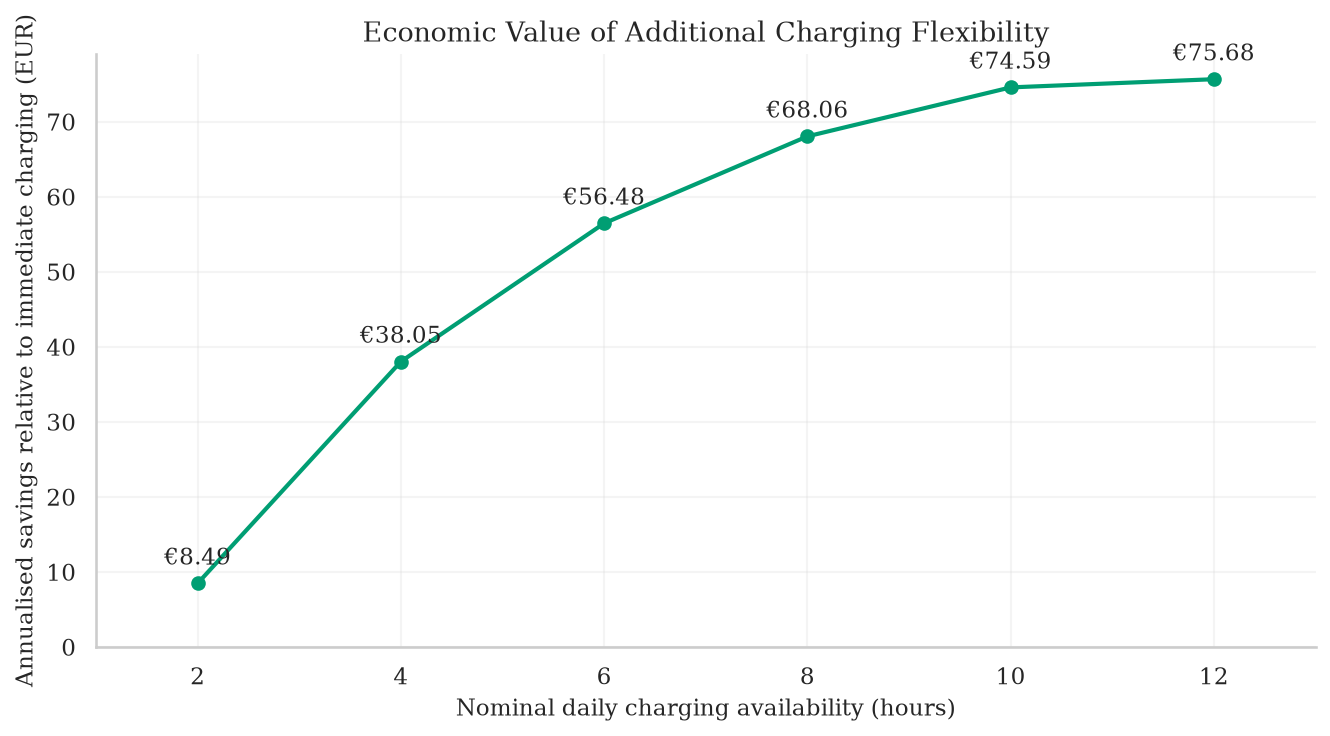

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

# Plot annual savings
ax.plot(
    duration_results.index,
    duration_results["annual_savings_eur"],
    color="#009E73",
    marker="o",
    markersize=6,
    linewidth=2
)

# Label every scenario
for duration, row in duration_results.iterrows():

    ax.annotate(
        f"€{row['annual_savings_eur']:.2f}",
        xy=(
            duration,
            row["annual_savings_eur"]
        ),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Economic Value of Additional Charging Flexibility"
)

ax.set_xlabel(
    "Nominal daily charging availability (hours)"
)

ax.set_ylabel(
    "Annualised savings relative to immediate charging (EUR)"
)

ax.set_xticks(availability_durations)
ax.set_ylim(bottom=0)
ax.margins(x=0.1, y=0.2)

fig.tight_layout()

save_figure(
    fig,
    "10_value_of_charging_flexibility"
)

plt.show()

#### 4.6 Marginal value of additional charging hours

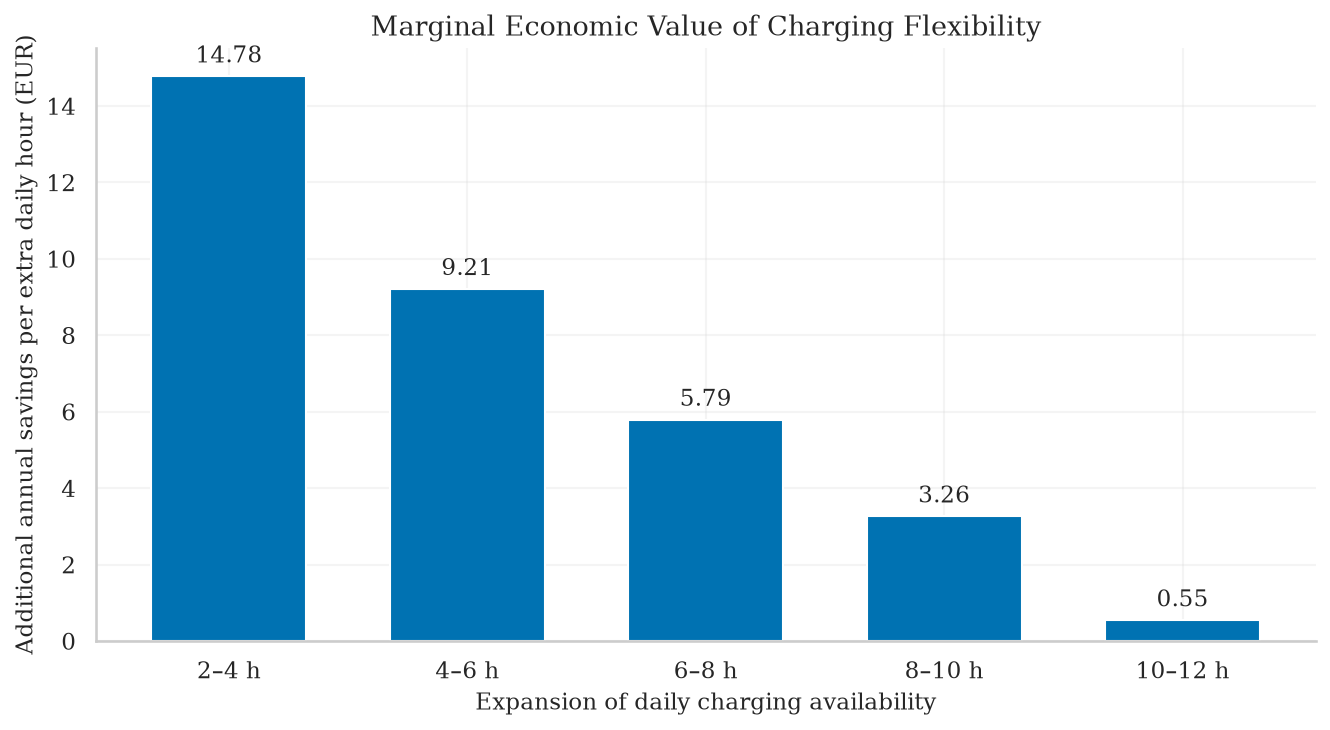

In [15]:
# Prepare marginal value data
marginal_plot = duration_results.dropna(
    subset=["marginal_value_eur_per_hour"]
).copy()

expansion_labels = [
    f"{int(h - 2)}–{int(h)} h"
    for h in marginal_plot.index
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    expansion_labels,
    marginal_plot["marginal_value_eur_per_hour"],
    color="#0072B2",
    width=0.65
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=4
)

ax.set_title(
    "Marginal Economic Value of Charging Flexibility"
)

ax.set_xlabel(
    "Expansion of daily charging availability"
)

ax.set_ylabel(
    "Additional annual savings per extra daily hour (EUR)"
)

ax.set_ylim(bottom=0)
ax.margins(y=0.15)

fig.tight_layout()

save_figure(
    fig,
    "11_marginal_value_of_flexibility"
)

plt.show()

## 5. Experiment B: Timing of Charging Flexibility

This experiment investigates whether equally long
charging windows generate different economic outcomes
depending on their temporal positioning.

Four hypothetical charging profiles are constructed,
each providing twelve nominal hours of daily
charging availability.

Electricity demand, maximum charging power,
battery parameters and tariff assumptions are
identical across profiles.

Both immediate and dynamically optimised charging
are simulated for each availability profile.

The analysis distinguishes cost savings within a
given availability window from differences in
optimised expenditure across alternative windows.

All scenarios use matched arrival dates.

The profiles represent controlled hypothetical
availability scenarios, not empirically observed
consumer mobility patterns.

In [16]:
# Define equal-duration charging profiles
timing_profiles = {
    "Early-day": 0,
    "Daytime": 6,
    "Afternoon/evening": 12,
    "Overnight": 18
}

timing_records = []
timing_session_records = []

for profile, start_hour in timing_profiles.items():

    # Construct twelve-hour availability window
    windows = build_charging_windows(
        start_hour=start_hour,
        duration_hours=12
    )

    # Simulate immediate and dynamic strategies
    immediate = simulate_window(
        windows,
        strategy="Immediate"
    )

    dynamic = simulate_window(
        windows,
        strategy="Dynamic"
    )

    # Check optimality for each session
    immediate_costs = immediate.set_index(
        "session_id"
    )["retail_cost_eur"]

    dynamic_costs = dynamic.set_index(
        "session_id"
    )["retail_cost_eur"]

    assert (
        dynamic_costs
        <= immediate_costs + TOLERANCE
    ).all()

    # Preserve detailed results
    immediate["profile"] = profile
    dynamic["profile"] = profile

    timing_session_records.extend([
        immediate,
        dynamic
    ])

    # Annualised results
    immediate_annual = annualise_results(
        immediate
    )

    dynamic_annual = annualise_results(
        dynamic
    )

    immediate_cost = immediate_annual[
        "annual_retail_cost_eur"
    ]

    dynamic_cost = dynamic_annual[
        "annual_retail_cost_eur"
    ]

    savings = immediate_cost - dynamic_cost

    timing_records.append({
        "profile": profile,

        "start_hour": start_hour,

        "nominal_duration_hours": 12,

        "annual_energy_kwh":
            dynamic_annual["annual_energy_kwh"],

        "immediate_cost_eur":
            immediate_cost,

        "dynamic_cost_eur":
            dynamic_cost,

        "within_window_savings_eur":
            savings,

        "within_window_savings_pct":
            savings / immediate_cost * 100,

        "cost_advantage_vs_overnight_eur":
            BASELINE_DYNAMIC_COST - dynamic_cost
    })

# Consolidate results
timing_results = (
    pd.DataFrame(timing_records)
    .set_index("profile")
)

timing_session_results = pd.concat(
    timing_session_records,
    ignore_index=True
)

# Verify reference overnight results
assert np.isclose(
    timing_results.loc[
        "Overnight", "dynamic_cost_eur"
    ],
    BASELINE_DYNAMIC_COST
)

assert np.isclose(
    timing_results.loc[
        "Overnight", "immediate_cost_eur"
    ],
    BASELINE_IMMEDIATE_COST
)

# Verify equivalent annual energy consumption
assert np.allclose(
    timing_results["annual_energy_kwh"],
    ANNUAL_HOME_GRID_ENERGY_KWH
)

display(timing_results.round(4))

print("Experiment B successfully completed.")
print("All timing sensitivity checks passed.")

,start_hour,nominal_duration_hours,annual_energy_kwh,immediate_cost_eur,dynamic_cost_eur,within_window_savings_eur,within_window_savings_pct,cost_advantage_vs_overnight_eur
profile,,,,,,,,
Early-day,0,12,1584.0,457.5508,394.2136,63.3372,13.8427,43.7211
Daytime,6,12,1584.0,477.1723,381.4471,95.7251,20.0609,56.4875
Afternoon/evening,12,12,1584.0,396.5903,378.2075,18.3828,4.6352,59.7271
Overnight,18,12,1584.0,513.6141,437.9346,75.6795,14.7347,0.0000


Experiment B successfully completed.
All timing sensitivity checks passed.


#### 5.1 Quantify the value of charging at different times

In [17]:
# Identify least expensive availability profile
cheapest_profile = timing_results[
    "dynamic_cost_eur"
].idxmin()

# Identify most expensive availability profile
most_expensive_profile = timing_results[
    "dynamic_cost_eur"
].idxmax()

# Calculate annual cost difference
timing_value = (
    timing_results["dynamic_cost_eur"].max()
    - timing_results["dynamic_cost_eur"].min()
)

# Compare daytime and overnight directly
daytime_advantage = (
    timing_results.loc[
        "Overnight", "dynamic_cost_eur"
    ]
    - timing_results.loc[
        "Daytime", "dynamic_cost_eur"
    ]
)

# Compare timing with additional overnight optimisation
overnight_incremental_dynamic_value = (
    reference_results.loc[
        "Fixed-time", "annual_retail_cost_eur"
    ]
    - reference_results.loc[
        "Dynamic", "annual_retail_cost_eur"
    ]
)

timing_value_summary = pd.Series({
    "Cheapest optimised profile":
        cheapest_profile,

    "Most expensive optimised profile":
        most_expensive_profile,

    "Maximum timing-related cost difference (EUR/year)":
        timing_value,

    "Daytime advantage over overnight (EUR/year)":
        daytime_advantage,

    "Incremental overnight optimisation value (EUR/year)":
        overnight_incremental_dynamic_value
}, name="Value")

display(timing_value_summary.to_frame())

,Value
Cheapest optimised profile,Afternoon/evening
Most expensive optimised profile,Overnight
Maximum timing-related cost difference (EUR/year),59.727135
Daytime advantage over overnight (EUR/year),56.487529
Incremental overnight optimisation value (EUR/year),19.990047


#### 5.2 Visualise the economic importance of timing

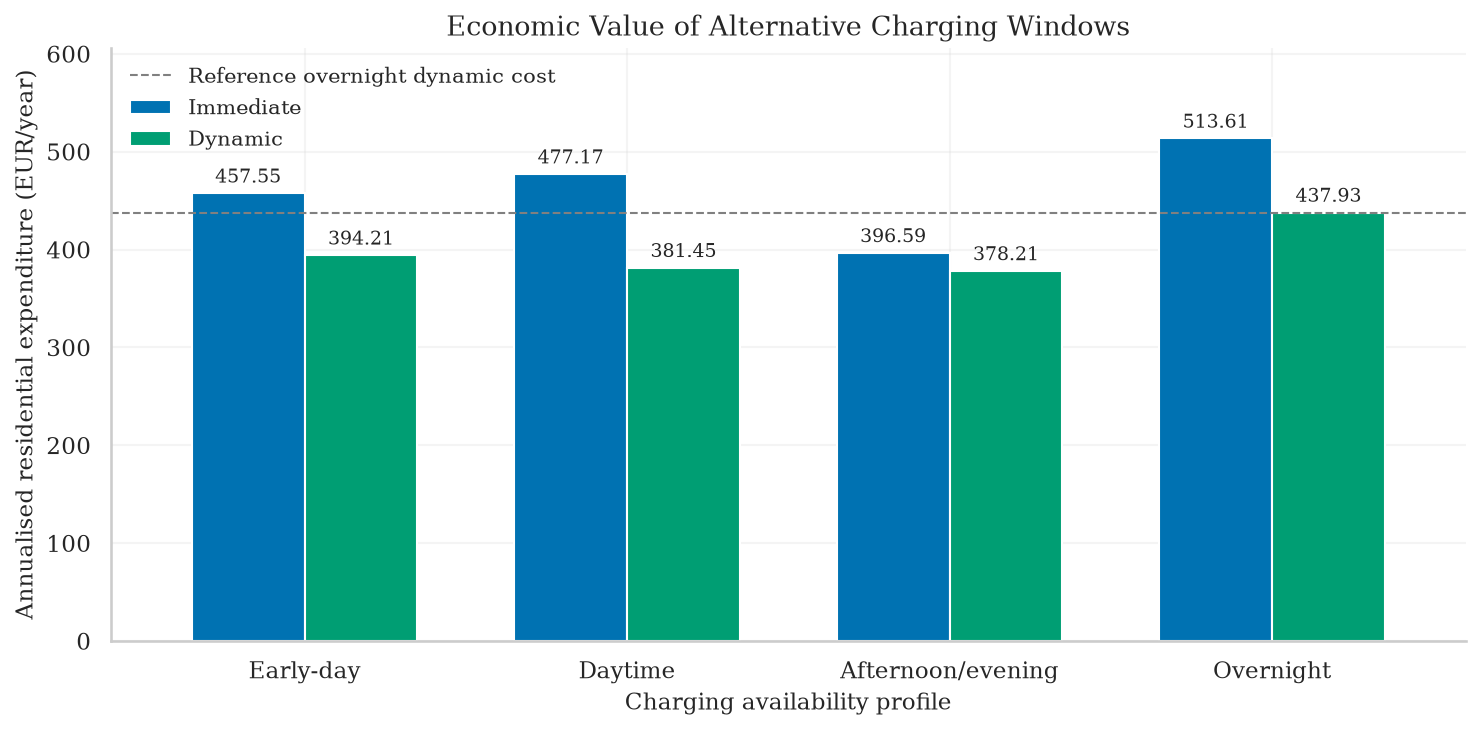

In [18]:
# Prepare comparison data
timing_plot = timing_results[
    [
        "immediate_cost_eur",
        "dynamic_cost_eur"
    ]
].copy()

timing_plot.columns = [
    "Immediate",
    "Dynamic"
]

fig, ax = plt.subplots(figsize=(10, 5))

timing_plot.plot(
    kind="bar",
    color=["#0072B2", "#009E73"],
    width=0.7,
    ax=ax
)

# Label expenditure bars
for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

# Reference dynamic overnight cost
ax.axhline(
    BASELINE_DYNAMIC_COST,
    color="grey",
    linestyle="--",
    linewidth=1,
    label="Reference overnight dynamic cost"
)

ax.set_title(
    "Economic Value of Alternative Charging Windows"
)

ax.set_xlabel("Charging availability profile")

ax.set_ylabel(
    "Annualised residential expenditure (EUR/year)"
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.margins(y=0.18)
ax.legend(frameon=False)

fig.tight_layout()

save_figure(
    fig,
    "12_timing_of_charging_flexibility"
)

plt.show()

#### 5.3 Seasonal value of charging timing

In [19]:
# Retain dynamically optimised sessions
dynamic_timing_sessions = (
    timing_session_results.loc[
        timing_session_results["strategy"] == "Dynamic"
    ].copy()
)

# Compare seasonal average daily expenditure
seasonal_timing_costs = (
    dynamic_timing_sessions
    .groupby(["season", "profile"])
    ["retail_cost_eur"]
    .mean()
    .unstack("profile")
    .reindex(
        index=season_order,
        columns=list(timing_profiles.keys())
    )
)

# Calculate cost advantage over overnight charging
seasonal_timing_advantage = (
    seasonal_timing_costs.rsub(
        seasonal_timing_costs["Overnight"],
        axis=0
    )
)

print("Seasonal optimised charging costs (EUR/day)")
display(seasonal_timing_costs.round(4))

print("Seasonal cost advantage over overnight (EUR/day)")
display(seasonal_timing_advantage.round(4))

Seasonal optimised charging costs (EUR/day)


profile,Early-day,Daytime,Afternoon/evening,Overnight
season,,,,
Winter,1.2229,1.2729,1.2464,1.2303
Spring,0.9879,0.8964,0.8964,1.2105
Summer,1.0067,0.9152,0.9150,1.2052
Autumn,1.1076,1.1038,1.0944,1.1537


Seasonal cost advantage over overnight (EUR/day)


profile,Early-day,Daytime,Afternoon/evening,Overnight
season,,,,
Winter,0.0073,-0.0426,-0.0161,0.0
Spring,0.2226,0.3141,0.3141,0.0
Summer,0.1986,0.2900,0.2902,0.0
Autumn,0.0461,0.0499,0.0593,0.0


#### 5.4 Visualise seasonal timing advantages

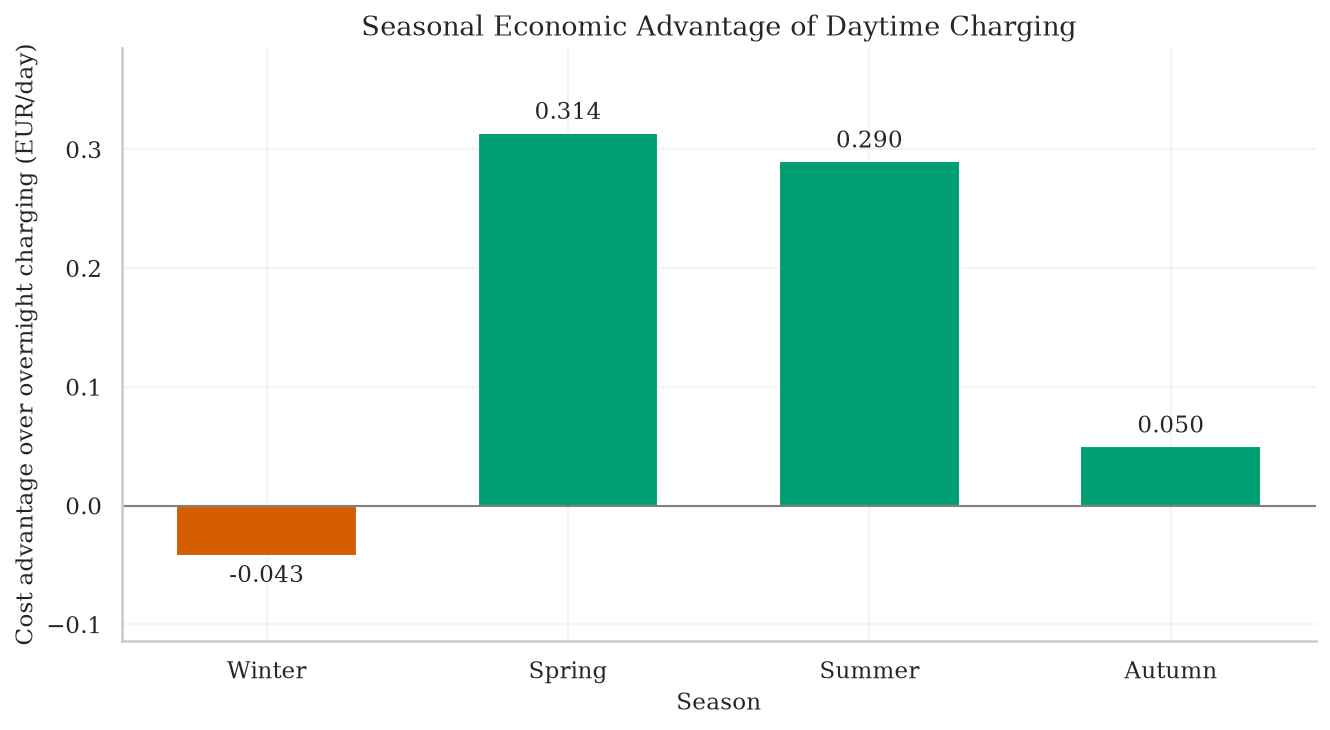

In [20]:
# Focus on the main daytime/overnight comparison
daytime_seasonal_advantage = (
    seasonal_timing_advantage["Daytime"]
)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    daytime_seasonal_advantage.index,
    daytime_seasonal_advantage.values,
    color=[
        "#009E73" if value >= 0 else "#D55E00"
        for value in daytime_seasonal_advantage
    ],
    width=0.6
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4
)

ax.axhline(
    0,
    color="grey",
    linewidth=1
)

ax.set_title(
    "Seasonal Economic Advantage of Daytime Charging"
)

ax.set_xlabel("Season")

ax.set_ylabel(
    "Cost advantage over overnight charging (EUR/day)"
)

ax.margins(y=0.2)

fig.tight_layout()

save_figure(
    fig,
    "13_seasonal_timing_advantage"
)

plt.show()

## 6. Export preliminary sensitivity results

In [21]:
# Experiment A: duration sensitivity
duration_results.to_csv(
    tables_dir / "flexibility_duration_results.csv"
)

duration_session_results.to_csv(
    processed_dir / "flexibility_duration_sessions.csv",
    index=False
)

# Experiment B: timing sensitivity
timing_results.to_csv(
    tables_dir / "flexibility_timing_results.csv"
)

timing_value_summary.to_csv(
    tables_dir / "flexibility_timing_value_summary.csv",
    header=True
)

timing_session_results.to_csv(
    processed_dir / "flexibility_timing_sessions.csv",
    index=False
)

# Seasonal timing analysis
seasonal_timing_costs.to_csv(
    tables_dir / "seasonal_timing_costs.csv"
)

seasonal_timing_advantage.to_csv(
    tables_dir / "seasonal_timing_advantage.csv"
)

print("Experiments A and B successfully exported.")

Experiments A and B successfully exported.


## 7. Experiment C: Electricity Tariff Sensitivity

This experiment investigates how alternative
time-invariant electricity tariff components
affect the economic benefits of smart charging.

The reference charging schedules are retained,
while constant tariff components are varied
between 10 and 30 ct/kWh.

These values represent hypothetical tariff
scenarios rather than observed commercial
electricity contracts.

The analysis distinguishes absolute electricity
cost savings from proportional reductions in
residential charging expenditure.

#### 7.1 Tariff sensitivity analysis

In [22]:
# Define illustrative tariff scenarios
tariff_scenarios = [0.10, 0.15, 0.20, 0.25, 0.30]

tariff_records = []

# Retrieve reference wholesale expenditure
spot_immediate = reference_results.loc[
    "Immediate", "annual_spot_cost_eur"
]

spot_fixed = reference_results.loc[
    "Fixed-time", "annual_spot_cost_eur"
]

spot_dynamic = reference_results.loc[
    "Dynamic", "annual_spot_cost_eur"
]

for charge in tariff_scenarios:

    constant_cost = (
        ANNUAL_HOME_GRID_ENERGY_KWH * charge
    )

    immediate_cost = spot_immediate + constant_cost
    fixed_cost = spot_fixed + constant_cost
    dynamic_cost = spot_dynamic + constant_cost

    dynamic_savings = immediate_cost - dynamic_cost

    tariff_records.append({
        "constant_charge_ct_kwh": charge * 100,

        "constant_annual_cost_eur": constant_cost,

        "immediate_cost_eur": immediate_cost,

        "fixed_time_cost_eur": fixed_cost,

        "dynamic_cost_eur": dynamic_cost,

        "dynamic_savings_eur": dynamic_savings,

        "dynamic_savings_pct":
            dynamic_savings / immediate_cost * 100,

        "incremental_dynamic_value_eur":
            fixed_cost - dynamic_cost
    })

tariff_results = (
    pd.DataFrame(tariff_records)
    .set_index("constant_charge_ct_kwh")
)

# Verify invariance of absolute savings
assert np.allclose(
    tariff_results["dynamic_savings_eur"],
    spot_immediate - spot_dynamic
)

# Verify reference scenario
assert np.isclose(
    tariff_results.loc[20, "dynamic_cost_eur"],
    BASELINE_DYNAMIC_COST
)

# Verify decreasing relative savings
assert (
    tariff_results["dynamic_savings_pct"]
    .diff()
    .dropna()
    < 0
).all()

display(tariff_results.round(4))

print("All tariff sensitivity checks passed.")

,constant_annual_cost_eur,immediate_cost_eur,fixed_time_cost_eur,dynamic_cost_eur,dynamic_savings_eur,dynamic_savings_pct,incremental_dynamic_value_eur
constant_charge_ct_kwh,,,,,,,
10.0,158.4,355.2141,299.5247,279.5346,75.6795,21.3053,19.99
15.0,237.6,434.4141,378.7247,358.7346,75.6795,17.4210,19.99
20.0,316.8,513.6141,457.9247,437.9346,75.6795,14.7347,19.99
25.0,396.0,592.8141,537.1247,517.1346,75.6795,12.7661,19.99
30.0,475.2,672.0141,616.3247,596.3346,75.6795,11.2616,19.99


All tariff sensitivity checks passed.


#### 7.2 Visualise tariff sensitivity

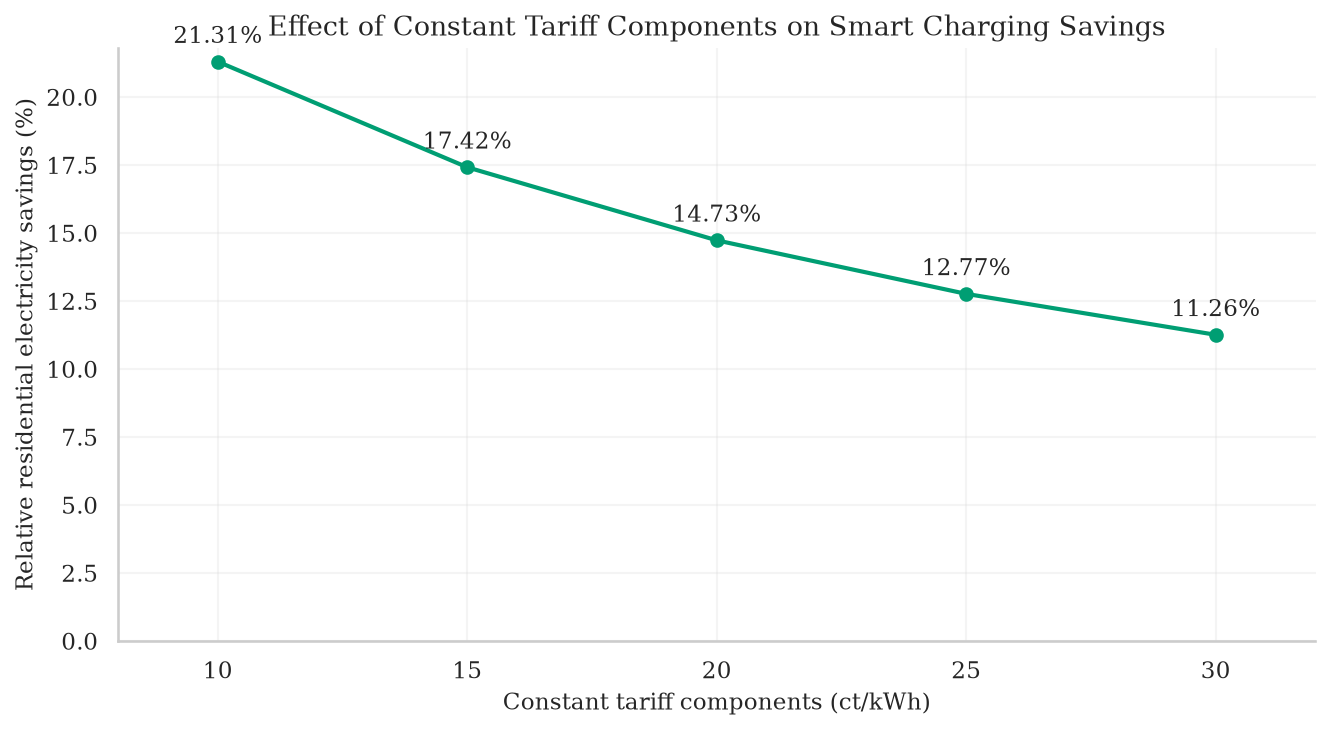

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    tariff_results.index,
    tariff_results["dynamic_savings_pct"],
    color="#009E73",
    marker="o",
    markersize=6,
    linewidth=2
)

for charge, row in tariff_results.iterrows():

    ax.annotate(
        f"{row['dynamic_savings_pct']:.2f}%",
        xy=(charge, row["dynamic_savings_pct"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Effect of Constant Tariff Components on Smart Charging Savings"
)

ax.set_xlabel(
    "Constant tariff components (ct/kWh)"
)

ax.set_ylabel(
    "Relative residential electricity savings (%)"
)

ax.set_xticks(tariff_results.index)
ax.set_ylim(bottom=0)
ax.margins(x=0.1, y=0.2)

fig.tight_layout()

save_figure(
    fig,
    "14_tariff_sensitivity"
)

plt.show()

## 8. Experiment D: Technical Robustness

This experiment examines the sensitivity of smart
charging expenditure to alternative charging
power limits and annual electricity requirements.

Each technical parameter is varied individually,
while all remaining reference assumptions are held
constant.

Lower charging power may require electricity
consumption to be distributed across multiple
hourly intervals, limiting the ability to
concentrate purchases in the cheapest period.

Higher electricity demand may increase the absolute
economic value of flexible charging.

All scenarios must satisfy the charging power,
energy requirement and battery constraints.

#### 8.1 Charging power sensitivity

In [24]:
charging_powers = [2.3, 3.7, 7.4, 11.0]

power_records = []

for power in charging_powers:

    # Simulate identical availability and energy demand
    immediate = simulate_window(
        reference_windows,
        strategy="Immediate",
        max_power=power
    )

    dynamic = simulate_window(
        reference_windows,
        strategy="Dynamic",
        max_power=power
    )

    immediate_annual = annualise_results(immediate)
    dynamic_annual = annualise_results(dynamic)

    immediate_cost = immediate_annual[
        "annual_retail_cost_eur"
    ]

    dynamic_cost = dynamic_annual[
        "annual_retail_cost_eur"
    ]

    savings = immediate_cost - dynamic_cost

    power_records.append({
        "charging_power_kw": power,

        "minimum_duration_hours":
            DAILY_GRID_ENERGY_KWH / power,

        "annual_energy_kwh":
            dynamic_annual["annual_energy_kwh"],

        "immediate_cost_eur":
            immediate_cost,

        "dynamic_cost_eur":
            dynamic_cost,

        "annual_savings_eur":
            savings,

        "retail_savings_pct":
            savings / immediate_cost * 100
    })

power_results = (
    pd.DataFrame(power_records)
    .set_index("charging_power_kw")
)

# Verify identical energy consumption
assert np.allclose(
    power_results["annual_energy_kwh"],
    ANNUAL_HOME_GRID_ENERGY_KWH
)

# Higher charging capacity cannot increase
# the minimum feasible expenditure
assert (
    power_results["dynamic_cost_eur"]
    .diff()
    .dropna()
    <= TOLERANCE
).all()

# Verify reference scenario
assert np.isclose(
    power_results.loc[11.0, "dynamic_cost_eur"],
    BASELINE_DYNAMIC_COST
)

display(power_results.round(4))

print("All charging power sensitivity checks passed.")

,minimum_duration_hours,annual_energy_kwh,immediate_cost_eur,dynamic_cost_eur,annual_savings_eur,retail_savings_pct
charging_power_kw,,,,,,
2.3,1.8868,1584.0,522.5740,440.0017,82.5723,15.8011
3.7,1.1729,1584.0,516.4242,438.5829,77.8413,15.0731
7.4,0.5864,1584.0,513.6141,437.9346,75.6795,14.7347
11.0,0.3945,1584.0,513.6141,437.9346,75.6795,14.7347


All charging power sensitivity checks passed.


#### 8.2 Annual energy demand sensitivity

In [25]:
energy_scenarios = [
    1000.0, 1584.0, 2500.0, 3000.0
]

energy_records = []

for annual_energy in energy_scenarios:

    immediate = simulate_window(
        reference_windows,
        strategy="Immediate",
        annual_energy=annual_energy
    )

    dynamic = simulate_window(
        reference_windows,
        strategy="Dynamic",
        annual_energy=annual_energy
    )

    immediate_annual = annualise_results(immediate)
    dynamic_annual = annualise_results(dynamic)

    immediate_cost = immediate_annual[
        "annual_retail_cost_eur"
    ]

    dynamic_cost = dynamic_annual[
        "annual_retail_cost_eur"
    ]

    savings = immediate_cost - dynamic_cost

    energy_records.append({
        "annual_energy_kwh": annual_energy,

        "daily_energy_kwh":
            annual_energy / DAYS_PER_YEAR,

        "immediate_cost_eur":
            immediate_cost,

        "dynamic_cost_eur":
            dynamic_cost,

        "annual_savings_eur":
            savings,

        "retail_savings_pct":
            savings / immediate_cost * 100,

        "savings_ct_per_kwh":
            savings / annual_energy * 100
    })

energy_results = (
    pd.DataFrame(energy_records)
    .set_index("annual_energy_kwh")
)

# Verify reference expenditure
assert np.isclose(
    energy_results.loc[1584.0, "dynamic_cost_eur"],
    BASELINE_DYNAMIC_COST
)

# Verify non-negative optimisation savings
assert (
    energy_results["annual_savings_eur"]
    >= -TOLERANCE
).all()

display(energy_results.round(4))

print("All energy demand sensitivity checks passed.")

,daily_energy_kwh,immediate_cost_eur,dynamic_cost_eur,annual_savings_eur,retail_savings_pct,savings_ct_per_kwh
annual_energy_kwh,,,,,,
1000.0,2.7397,324.2513,276.4739,47.7774,14.7347,4.7777
1584.0,4.3397,513.6141,437.9346,75.6795,14.7347,4.7777
2500.0,6.8493,810.6283,691.1847,119.4436,14.7347,4.7777
3000.0,8.2192,972.7540,829.4217,143.3323,14.7347,4.7777


All energy demand sensitivity checks passed.


#### 8.3 Visualise technical robustness

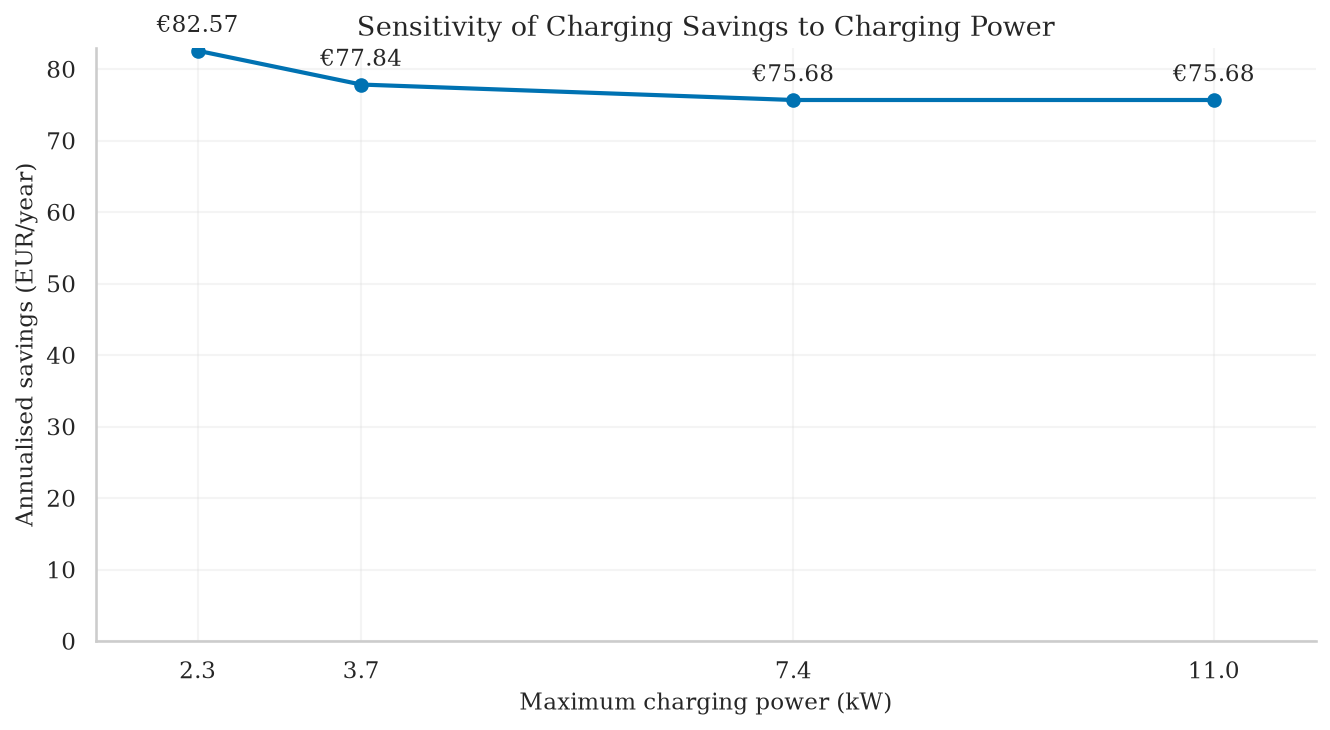

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    power_results.index,
    power_results["annual_savings_eur"],
    color="#0072B2",
    marker="o",
    linewidth=2
)

for power, row in power_results.iterrows():

    ax.annotate(
        f"€{row['annual_savings_eur']:.2f}",
        xy=(power, row["annual_savings_eur"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Sensitivity of Charging Savings to Charging Power"
)

ax.set_xlabel("Maximum charging power (kW)")
ax.set_ylabel("Annualised savings (EUR/year)")

ax.set_xticks(charging_powers)
ax.set_ylim(bottom=0)
ax.margins(x=0.1, y=0.2)

fig.tight_layout()

save_figure(fig, "15_charging_power_sensitivity")

plt.show()

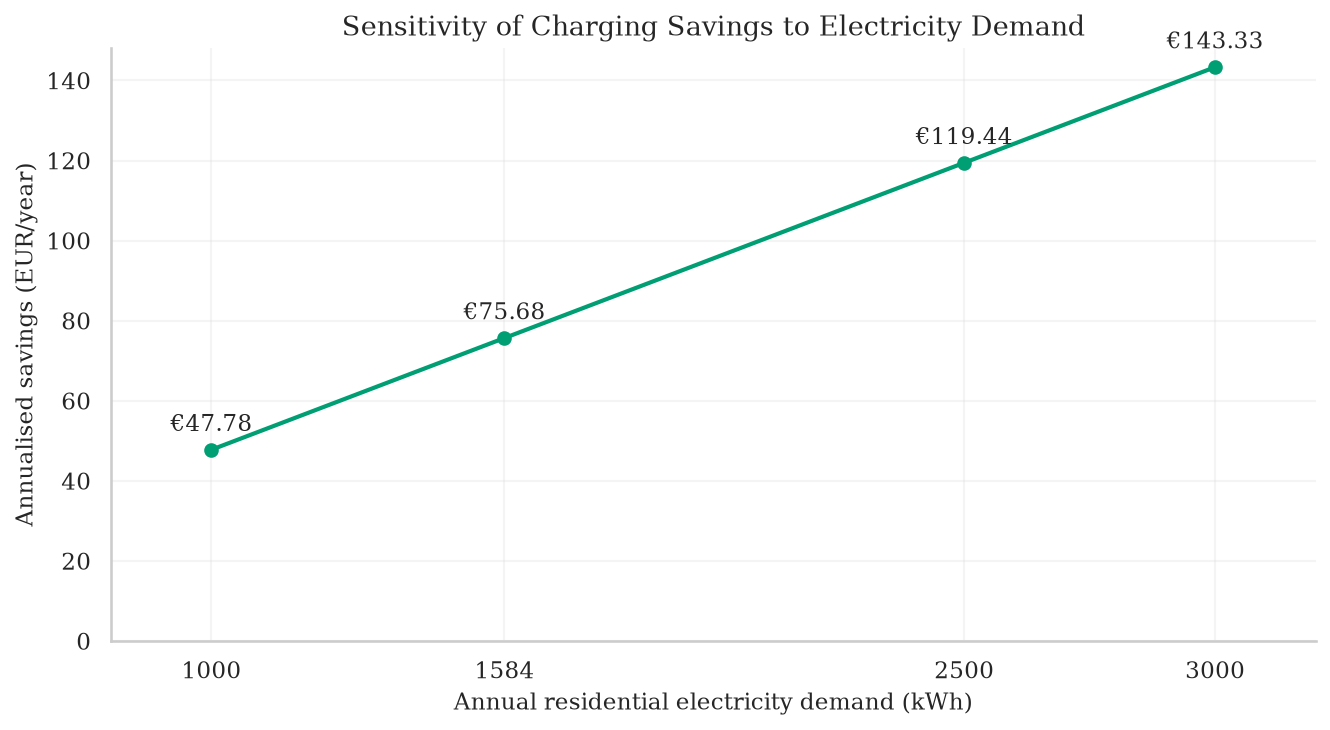

In [27]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    energy_results.index,
    energy_results["annual_savings_eur"],
    color="#009E73",
    marker="o",
    linewidth=2
)

for energy, row in energy_results.iterrows():

    ax.annotate(
        f"€{row['annual_savings_eur']:.2f}",
        xy=(energy, row["annual_savings_eur"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center"
    )

ax.set_title(
    "Sensitivity of Charging Savings to Electricity Demand"
)

ax.set_xlabel(
    "Annual residential electricity demand (kWh)"
)

ax.set_ylabel(
    "Annualised savings (EUR/year)"
)

ax.set_xticks(energy_scenarios)
ax.set_ylim(bottom=0)
ax.margins(x=0.1, y=0.2)

fig.tight_layout()

save_figure(fig, "16_energy_demand_sensitivity")

plt.show()

## 9. Export remaining sensitivity results

In [28]:
tariff_results.to_csv(
    tables_dir / "tariff_sensitivity_results.csv"
)

power_results.to_csv(
    tables_dir / "charging_power_sensitivity_results.csv"
)

energy_results.to_csv(
    tables_dir / "energy_demand_sensitivity_results.csv"
)

print("Experiments C and D successfully exported.")

Experiments C and D successfully exported.


## 10. Economic Interpretation and Key Findings

### 10.1 Quantity of Charging Flexibility

The sensitivity analysis reveals a nonlinear relationship between charging availability and annualised electricity cost savings.

Increasing nominal daily charging availability from two to twelve hours increases annualised savings from EUR 8.49 to EUR 75.68.

The marginal economic value of additional availability decreases consistently across the evaluated two-hour expansions, declining from EUR 14.78 to EUR 0.55 in additional annual savings per extra hour of daily availability.

Eight hours of availability capture 89.93% of the savings achievable with twelve hours, while ten hours capture 98.56%.

These findings support H2 within the evaluated scenarios and suggest that maximising the duration of consumer flexibility is not necessarily required to capture most of its economic benefits.

However, the welfare-maximising quantity of flexibility cannot be determined without incorporating consumer inconvenience and opportunity costs.

### 10.2 Timing of Charging Flexibility

Four hypothetical charging profiles with identical nominal availability durations of twelve hours are compared.

| Availability profile | Immediate expenditure (EUR/year) | Dynamic expenditure (EUR/year) | Within-window savings (EUR/year) |
|---|---:|---:|---:|
| Early-day | 457.55 | 394.21 | 63.34 |
| Daytime | 477.17 | 381.45 | 95.73 |
| Afternoon/evening | 396.59 | 378.21 | 18.38 |
| Overnight | 513.61 | 437.93 | 75.68 |

The difference between the least and most expensive optimised charging profiles amounts to EUR 59.73 annually.

Changing from overnight to daytime availability reduces optimised charging expenditure by EUR 56.49 annually, approximately 2.83 times the incremental economic benefit of replacing fixed-time overnight charging with dynamic optimisation.

The findings support H4 within the evaluated scenarios, demonstrating that the economic value of charging flexibility depends on its temporal positioning rather than solely on its duration.

The comparison also reveals that the profile with the lowest optimised expenditure does not necessarily generate the largest savings relative to immediate charging. Economic assessments must therefore distinguish absolute expenditure from savings relative to a particular benchmark.

### 10.3 Seasonal Differences in the Value of Timing

The economic advantage of daytime charging varies considerably across seasons.

| Season | Daytime cost advantage over overnight charging (EUR/day) |
|---|---:|
| Winter | −0.0426 |
| Spring | 0.3141 |
| Summer | 0.2900 |
| Autumn | 0.0499 |

Daytime availability is economically advantageous during spring, summer and autumn, whereas overnight availability performs slightly better during winter.

These findings are consistent with the seasonal electricity price dynamics identified in the exploratory analysis.

They suggest that the economic usefulness of consumer flexibility depends on its alignment with changing electricity market conditions.

### 10.4 Electricity Tariff Sensitivity

Varying constant tariff components between 10 and 30 ct/kWh leaves absolute annualised smart-charging savings unchanged at EUR 75.68.

However, relative residential electricity savings decline from 21.31% to 11.26%.

This relationship follows mathematically from the identical electricity quantities purchased under each charging strategy.

The results highlight the importance of distinguishing absolute economic benefits from percentage savings when comparing alternative tariff structures and findings from existing studies.

### 10.5 Charging Power Sensitivity

| Charging power (kW) | Immediate expenditure (EUR/year) | Dynamic expenditure (EUR/year) | Savings (EUR/year) |
|---|---:|---:|---:|
| 2.3 | 522.57 | 440.00 | 82.57 |
| 3.7 | 516.42 | 438.58 | 77.84 |
| 7.4 | 513.61 | 437.93 | 75.68 |
| 11.0 | 513.61 | 437.93 | 75.68 |

Lower charging powers generate larger savings relative to immediate charging, despite resulting in higher optimised electricity expenditure.

This apparent paradox arises because immediate charging costs are more sensitive to reduced charging power than optimised charging costs under the observed electricity prices.

The identical economic outcomes at 7.4 and 11 kW reflect technical saturation within the hourly model, as both charging powers can satisfy the complete daily energy requirement within a single hourly interval.

These findings cannot automatically be generalised to finer temporal resolutions or different electricity requirements.

### 10.6 Electricity Demand Sensitivity

Annualised savings increase from EUR 47.78 at a residential electricity demand of 1,000 kWh to EUR 143.33 at 3,000 kWh.

Relative savings remain constant at 14.73%, corresponding to approximately 4.78 ct/kWh.

This proportional relationship follows from the ability to satisfy the complete daily energy requirement within a single hourly interval across all tested demand scenarios.

The result illustrates the potential relevance of electricity consumption for the economic attractiveness of fixed-fee charging optimisation services.

### 10.7 Overall Economic Implications

The sensitivity analysis identifies three distinct mechanisms of economic value creation:

1. Expanding the quantity of charging availability.
2. Improving the temporal alignment of charging availability with electricity market opportunities.
3. Increasing the sophistication of charging optimisation.

The results suggest that these mechanisms should be considered jointly when designing consumer-oriented flexibility services.

In particular, improving access to economically attractive charging periods may generate greater electricity cost reductions than increasing the sophistication of optimisation within an existing availability window.

The economic value of additional flexibility should nevertheless be evaluated against the costs and inconvenience associated with providing it.

### 10.8 Limitations

The sensitivity scenarios represent hypothetical consumer profiles rather than empirically observed mobility behaviour.

All experiments retain a simplified session-based charging model, constant daily energy requirements within each scenario and perfect knowledge of the relevant hourly electricity prices.

Charging windows have identical nominal durations in the timing experiment, although elapsed durations may differ on daylight-saving transition days.

The analysis does not incorporate the costs of changing charging locations, installing infrastructure, adapting mobility schedules or providing additional flexibility.

The tariff scenarios assume full transmission of wholesale price variations through an additive residential tariff with time-invariant additional charges.

All results are conditional on the historical electricity prices of the Germany–Luxembourg market in 2025 and cannot automatically be generalised to other markets or future periods.

**Source:** Own sensitivity analysis based on historical Germany–Luxembourg day-ahead electricity prices retrieved from the Fraunhofer ISE Energy-Charts API, with reference vehicle parameters adapted from Lohr et al. (2025).

In [29]:
# Consolidate the principal economic findings

key_findings = pd.DataFrame([
    {
        "indicator": "Dynamic overnight savings",
        "value": BASELINE_IMMEDIATE_COST
                 - BASELINE_DYNAMIC_COST,
        "unit": "EUR/year",
        "source": "Notebook 02"
    },
    {
        "indicator": "Incremental value over midnight timer",
        "value": overnight_incremental_dynamic_value,
        "unit": "EUR/year",
        "source": "Notebook 02"
    },
    {
        "indicator": "Savings captured with 8 hours",
        "value": duration_results.loc[
            8, "reference_savings_captured_pct"
        ],
        "unit": "%",
        "source": "Experiment A"
    },
    {
        "indicator": "Additional value from 10 to 12 hours",
        "value": duration_results.loc[
            12, "incremental_savings_eur"
        ],
        "unit": "EUR/year",
        "source": "Experiment A"
    },
    {
        "indicator": "Daytime advantage over overnight",
        "value": daytime_advantage,
        "unit": "EUR/year",
        "source": "Experiment B"
    },
    {
        "indicator": "Maximum timing-related cost difference",
        "value": timing_value,
        "unit": "EUR/year",
        "source": "Experiment B"
    },
    {
        "indicator": "Relative savings at 10 ct/kWh",
        "value": tariff_results.loc[
            10, "dynamic_savings_pct"
        ],
        "unit": "%",
        "source": "Experiment C"
    },
    {
        "indicator": "Relative savings at 30 ct/kWh",
        "value": tariff_results.loc[
            30, "dynamic_savings_pct"
        ],
        "unit": "%",
        "source": "Experiment C"
    },
    {
        "indicator": "Savings per kWh at reference demand",
        "value": energy_results.loc[
            1584, "savings_ct_per_kwh"
        ],
        "unit": "ct/kWh",
        "source": "Experiment D"
    }
])

assert key_findings["value"].notna().all()

display(key_findings.round(4))

key_findings.to_csv(
    tables_dir / "consolidated_research_findings.csv",
    index=False
)

print("Sensitivity analysis completed.")
print("Consolidated research findings exported.")

,indicator,value,unit,source
0,Dynamic overnight savings,75.6795,EUR/year,Notebook 02
1,Incremental value over midnight timer,19.9900,EUR/year,Notebook 02
2,Savings captured with 8 hours,89.9333,%,Experiment A
3,Additional value from 10 to 12 hours,1.0906,EUR/year,Experiment A
4,Daytime advantage over overnight,56.4875,EUR/year,Experiment B
5,Maximum timing-related cost difference,59.7271,EUR/year,Experiment B
6,Relative savings at 10 ct/kWh,21.3053,%,Experiment C
7,Relative savings at 30 ct/kWh,11.2616,%,Experiment C
8,Savings per kWh at reference demand,4.7777,ct/kWh,Experiment D


Sensitivity analysis completed.
Consolidated research findings exported.
